# NLDC Research Project: Weeks 9, 10 & 11 Combined Task
## Hyperchaotic Lü System Synchronization Study
**Team Members:** Khushi (LCS2024018), Suhani Thakur (LCI2024029), Vennela Varshini Anasoori (LCB2024021), Gubba Pavani (LIT2024035)

---
### Project Overview & Objectives
1. **Week 9: Parameter Recalibration ($\alpha, \beta, p, q$)**
   - Resolve the Week 8 prototype failure (unsettled at 10s, stalled error floor $\approx 3.03 \times 10^{-3}$).
   - Account for the unactuated state $e_1$ via virtual control backstepping.
   - Calibrate feedback parameters $(\alpha, \beta, p, q)$ to prove that hyperchaotic Lü systems CAN converge in fixed time.
2. **Week 10: Robustness & Sensitivity Analysis**
   - Evaluate convergence across 4 initial condition levels (small, moderate, large, extreme offsets) to verify the Fixed-Time Stability Theorem ($t_s \le T_{max}$ independent of $\|e(0)\|$).
   - Test disturbance rejection under constant, sinusoidal, and high-frequency stochastic noise.
   - Test parameter uncertainty robustness under $\pm 15\%$ variations in $b_1, b_2, b_3, b_4$.
3. **Week 11: Benchmark Controller Comparison**
   - Compare the **2026 Paper Controller** (Lyapunov FTSC: single power-law + hyperbolic feedback by Shafiq & Ahmad) against the **2022 Paper Controller** (Adaptive Backstepping FTSC with unknown parameters by Wang & Ai).
   - Quantify: Synchronization time ($t_s$), convergence rate, peak control, total control effort (energy), and integral indices (ISE, IAE, ITAE).

In [2]:
# Install dependencies (if running in Colab environment)
!pip install -q numpy scipy matplotlib

import numpy as np
import scipy.integrate as spi
import matplotlib.pyplot as plt

# Visual styling for publication-grade figures
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Helvetica, Arial, DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
print("Libraries successfully imported!")

Libraries successfully imported!


## 1. System Dynamics & Theoretical Formulation
The 4D Hyperchaotic Lü System is given by:
$$\begin{aligned}
\dot{x}_1 &= -b_1 x_2 \\
\dot{x}_2 &= b_2(x_3 - x_2 + x_3 x_4) \\
\dot{x}_3 &= -x_2 x_4 + b_3 x_3 + x_1 \\
\dot{x}_4 &= x_2 x_3 - b_4 x_4
\end{aligned}$$

Nominal chaotic parameters: $b_1 = 5.0, b_2 = 35.0, b_3 = 14.0, b_4 = 3.0$.

The Slave (Response) System with control inputs $u_1, u_2, u_3$ applied to states 2, 3, 4:
$$\begin{aligned}
\dot{\bar{x}}_1 &= -b_1 \bar{x}_2 \\
\dot{\bar{x}}_2 &= b_2(\bar{x}_3 - \bar{x}_2 + \bar{x}_3 \bar{x}_4) + u_1 + d_1(t) \\
\dot{\bar{x}}_3 &= -\bar{x}_2 \bar{x}_4 + b_3 \bar{x}_3 + \bar{x}_1 + u_2 + d_2(t) \\
\dot{\bar{x}}_4 &= \bar{x}_2 \bar{x}_3 - b_4 \bar{x}_4 + u_3 + d_3(t)
\end{aligned}$$

**Underactuated State Insight:** State 1 has no direct control actuator ($\dot{e}_1 = -b_1 e_2$). To synchronize $e_1$, state $e_2$ must act as a virtual actuator: $e_2 \to \alpha_1(e_1)$. In Week 8, neglecting this virtual control caused $e_1$ to freeze and stalled convergence at $3.03 \times 10^{-3}$.

In [3]:
b_nom = np.array([5.0, 35.0, 14.0, 3.0])

def sig(x, p):
    return np.sign(x) * (np.abs(x) ** p)

def smooth_sig(x, p, delta=1e-4):
    abs_x = np.abs(x)
    return np.where(abs_x >= delta, 
                    np.sign(x) * (abs_x ** p),
                    x / (delta ** (1.0 - p)))

def master_dynamics(t, x, b=b_nom):
    return np.array([
        -b[0] * x[1],
        b[1] * (x[2] - x[1] + x[2] * x[3]),
        -x[1] * x[3] + b[2] * x[2] + x[0],
        x[1] * x[2] - b[3] * x[3]
    ])

print("Master equations ready.")

Master equations ready.


## 2. Core Simulation Engine
This unified simulation engine supports all 4 controllers:
1. `week8_uncalibrated`: Original uncalibrated prototype without $e_1$ coupling.
2. `recalibrated_lyapunov`: Recalibrated fixed-time Lyapunov with backstepping virtual control.
3. `2026_paper`: Shafiq & Ahmad (AMC 2026) single power law + hyperbolic feedback.
4. `2022_adaptive_backstepping`: Wang & Ai (AMC 2022) adaptive backstepping with unknown parameters.

In [4]:
def simulate(ctrl_name, t_max=10.0, steps=2500, x0_m=None, x0_s=None, 
             b_actual=b_nom, dist_type=None, **params):
    if x0_m is None:
        x0_m = np.array([1.0, 2.0, 3.0, 4.0])
    if x0_s is None:
        x0_s = np.array([2.0, -1.0, 4.0, 1.0])
        
    t_eval = np.linspace(0, t_max, steps)
    dt = t_eval[1] - t_eval[0]
    
    alpha = params.get('alpha', 5.0)
    beta = params.get('beta', 5.0)
    p = params.get('p', 1.2)
    q = params.get('q', 0.7)
    gamma_tanh = params.get('gamma', 5.0)
    k_lin = params.get('k', 8.0)
    c1 = params.get('c1', 3.0)
    delta = params.get('delta', 1e-4)
    
    X_m = np.zeros((steps, 4))
    X_s = np.zeros((steps, 4))
    U = np.zeros((steps, 3))
    E = np.zeros((steps, 4))
    b_hat_hist = np.zeros((steps, 4))
    b_hat = np.array([3.0, 25.0, 10.0, 2.0])
    
    curr_xm = x0_m.copy()
    curr_xs = x0_s.copy()
    
    for i, t in enumerate(t_eval):
        e = curr_xs - curr_xm
        E[i] = e
        X_m[i] = curr_xm
        X_s[i] = curr_xs
        
        # Disturbances
        if dist_type == "constant":
            d = np.array([1.0, 1.0, 1.0])
        elif dist_type == "sinusoidal":
            d = np.array([2.0 * np.sin(3.0 * t), 2.0 * np.cos(3.0 * t), 1.5 * np.sin(2.0 * t)])
        elif dist_type == "noisy":
            np.random.seed(i)
            d = np.array([1.2 * np.sin(25.0 * t) + 0.3 * np.random.randn(),
                          1.2 * np.cos(25.0 * t) + 0.3 * np.random.randn(),
                          0.8 * np.sin(20.0 * t) + 0.3 * np.random.randn()])
        else:
            d = np.zeros(3)
            
        b1, b2, b3, b4 = b_actual
        
        if ctrl_name == "week8_uncalibrated":
            u1 = -b2 * (curr_xs[2] - curr_xs[1] + curr_xs[2]*curr_xs[3]) + b2 * (curr_xm[2] - curr_xm[1] + curr_xm[2]*curr_xm[3]) \
                 - 1.0 * sig(e[1], 1.5) - 1.0 * sig(e[1], 0.5)
            u2 = (curr_xs[1]*curr_xs[3] - b3*curr_xs[2] - curr_xs[0]) - (curr_xm[1]*curr_xm[3] - b3*curr_xm[2] - curr_xm[0]) \
                 - 1.0 * sig(e[2], 1.5) - 1.0 * sig(e[2], 0.5)
            u3 = -(curr_xs[1]*curr_xs[2] - b4*curr_xs[3]) + (curr_xm[1]*curr_xm[2] - b4*curr_xm[3]) \
                 - 1.0 * sig(e[3], 1.5) - 1.0 * sig(e[3], 0.5)
                 
        elif ctrl_name == "recalibrated_lyapunov":
            alpha1 = (c1 * e[0] + alpha * smooth_sig(e[0], p, delta) + beta * smooth_sig(e[0], q, delta)) / b1
            z2 = e[1] - alpha1
            d_a1 = (c1 + alpha * p * (np.abs(e[0])**(p-1) if np.abs(e[0]) >= delta else delta**(p-1)) + \
                         beta * q * (np.abs(e[0])**(q-1) if np.abs(e[0]) >= delta else delta**(q-1))) / b1
            d_alpha1_dt = d_a1 * (-b1 * e[1])
            
            u1 = -b2 * (curr_xs[2] - curr_xs[1] + curr_xs[2]*curr_xs[3]) + b2 * (curr_xm[2] - curr_xm[1] + curr_xm[2]*curr_xm[3]) \
                 + d_alpha1_dt - k_lin * z2 - alpha * smooth_sig(z2, p, delta) - beta * smooth_sig(z2, q, delta) + b1 * e[0]
            u2 = (curr_xs[1]*curr_xs[3] - b3*curr_xs[2] - curr_xs[0]) - (curr_xm[1]*curr_xm[3] - b3*curr_xm[2] - curr_xm[0]) \
                 - k_lin * e[2] - alpha * smooth_sig(e[2], p, delta) - beta * smooth_sig(e[2], q, delta)
            u3 = -(curr_xs[1]*curr_xs[2] - b4*curr_xs[3]) + (curr_xm[1]*curr_xm[2] - b4*curr_xm[3]) \
                 - k_lin * e[3] - alpha * smooth_sig(e[3], p, delta) - beta * smooth_sig(e[3], q, delta)
                 
        elif ctrl_name == "2026_paper":
            alpha1 = (c1 * e[0] + alpha * sig(e[0], p) + beta * np.tanh(gamma_tanh * e[0])) / b1
            z2 = e[1] - alpha1
            d_a1 = (c1 + alpha * p * (np.abs(e[0])**(p-1)) + beta * gamma_tanh * (1.0 - np.tanh(gamma_tanh * e[0])**2)) / b1
            d_alpha1_dt = d_a1 * (-b1 * e[1])
            
            u1 = -b2 * (curr_xs[2] - curr_xs[1] + curr_xs[2]*curr_xs[3]) + b2 * (curr_xm[2] - curr_xm[1] + curr_xm[2]*curr_xm[3]) \
                 + d_alpha1_dt - k_lin * z2 - alpha * sig(z2, p) - beta * np.tanh(gamma_tanh * z2) + b1 * e[0]
            u2 = (curr_xs[1]*curr_xs[3] - b3*curr_xs[2] - curr_xs[0]) - (curr_xm[1]*curr_xm[3] - b3*curr_xm[2] - curr_xm[0]) \
                 - k_lin * e[2] - alpha * sig(e[2], p) - beta * np.tanh(gamma_tanh * e[2])
            u3 = -(curr_xs[1]*curr_xs[2] - b4*curr_xs[3]) + (curr_xm[1]*curr_xm[2] - b4*curr_xm[3]) \
                 - k_lin * e[3] - alpha * sig(e[3], p) - beta * np.tanh(gamma_tanh * e[3])
                 
        elif ctrl_name == "2022_adaptive_backstepping":
            b_hat_hist[i] = b_hat
            b_h1 = max(b_hat[0], 0.5)
            alpha1 = (c1 * e[0] + alpha * smooth_sig(e[0], p, delta) + beta * smooth_sig(e[0], q, delta)) / b_h1
            z2 = e[1] - alpha1
            d_a1 = (c1 + alpha * p * (np.abs(e[0])**(p-1) if np.abs(e[0]) >= delta else delta**(p-1)) + \
                         beta * q * (np.abs(e[0])**(q-1) if np.abs(e[0]) >= delta else delta**(q-1))) / b_h1
            d_alpha1_dt = d_a1 * (-b_actual[0] * e[1])
            
            u1 = -b_hat[1] * (curr_xs[2] - curr_xs[1] + curr_xs[2]*curr_xs[3]) + b_hat[1] * (curr_xm[2] - curr_xm[1] + curr_xm[2]*curr_xm[3]) \
                 + d_alpha1_dt - k_lin * z2 - alpha * smooth_sig(z2, p, delta) - beta * smooth_sig(z2, q, delta) + b_h1 * e[0]
            u2 = (curr_xs[1]*curr_xs[3] - b_hat[2]*curr_xs[2] - curr_xs[0]) - (curr_xm[1]*curr_xm[3] - b_hat[2]*curr_xm[2] - curr_xm[0]) \
                 - k_lin * e[2] - alpha * smooth_sig(e[2], p, delta) - beta * smooth_sig(e[2], q, delta)
            u3 = -(curr_xs[1]*curr_xs[2] - b_hat[3]*curr_xs[3]) + (curr_xm[1]*curr_xm[2] - b_hat[3]*curr_xm[3]) \
                 - k_lin * e[3] - alpha * smooth_sig(e[3], p, delta) - beta * smooth_sig(e[3], q, delta)
                 
            gamma_a = 4.0
            db_hat = np.array([
                gamma_a * e[0] * z2 - 0.05 * (b_hat[0] - b_nom[0]),
                gamma_a * z2 * (curr_xs[2] - curr_xs[1] + curr_xs[2]*curr_xs[3] - (curr_xm[2] - curr_xm[1] + curr_xm[2]*curr_xm[3])) - 0.05 * (b_hat[1] - b_nom[1]),
                gamma_a * e[2] * (curr_xs[2] - curr_xm[2]) - 0.05 * (b_hat[2] - b_nom[2]),
                gamma_a * e[3] * (-(curr_xs[3] - curr_xm[3])) - 0.05 * (b_hat[3] - b_nom[3])
            ])
            b_hat = b_hat + db_hat * dt
            
        U[i] = np.array([u1, u2, u3])
        
        dxm = master_dynamics(t, curr_xm, b_actual)
        dxs = np.array([
            -b1 * curr_xs[1],
            b2 * (curr_xs[2] - curr_xs[1] + curr_xs[2]*curr_xs[3]) + u1 + d[0],
            -curr_xs[1]*curr_xs[3] + b3*curr_xs[2] + curr_xs[0] + u2 + d[1],
            curr_xs[1]*curr_xs[2] - b4*curr_xs[3] + u3 + d[2]
        ])
        curr_xm += dxm * dt
        curr_xs += dxs * dt

    err_norm = np.linalg.norm(E, axis=1)
    tol = 1e-3
    settled_idx = np.where(err_norm <= tol)[0]
    if len(settled_idx) > 0 and settled_idx[-1] == steps - 1:
        ts = t_eval[settled_idx[0]]
    else:
        ts = np.nan
        
    ctrl_effort = np.trapz(np.sum(U**2, axis=1), t_eval)
    peak_u = np.max(np.abs(U))
    final_err = err_norm[-1]
    ise = np.trapz(err_norm**2, t_eval)
    iae = np.trapz(err_norm, t_eval)
    itae = np.trapz(t_eval * err_norm, t_eval)
    
    return {
        't': t_eval, 'err_norm': err_norm, 'E': E, 'U': U, 
        'X_m': X_m, 'X_s': X_s, 'b_hat_hist': b_hat_hist,
        'ts': ts, 'ctrl_effort': ctrl_effort, 'peak_u': peak_u,
        'final_err': final_err, 'ise': ise, 'iae': iae, 'itae': itae
    }

print("Unified simulator loaded!")

Unified simulator loaded!


## 3. Week 9 Task: Parameter Recalibration $(\alpha, \beta, p, q)$
Run this cell to compare the Week 8 prototype with the Recalibrated Lyapunov and 2026 Paper controllers.

/var/folders/k0/g7h2q2sx6bl_c5wh7vk5pjnc0000gn/T/ipykernel_10203/3093057918.py:131: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  ctrl_effort = np.trapz(np.sum(U**2, axis=1), t_eval)
/var/folders/k0/g7h2q2sx6bl_c5wh7vk5pjnc0000gn/T/ipykernel_10203/3093057918.py:134: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  ise = np.trapz(err_norm**2, t_eval)
/var/folders/k0/g7h2q2sx6bl_c5wh7vk5pjnc0000gn/T/ipykernel_10203/3093057918.py:135: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  iae = np.trapz(err_norm, t_eval)
/var/folders/k0/g7h2q2sx6bl_c5wh7vk5pjnc0000gn/T/ipykernel_10203/3093057918.py:136: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.inte

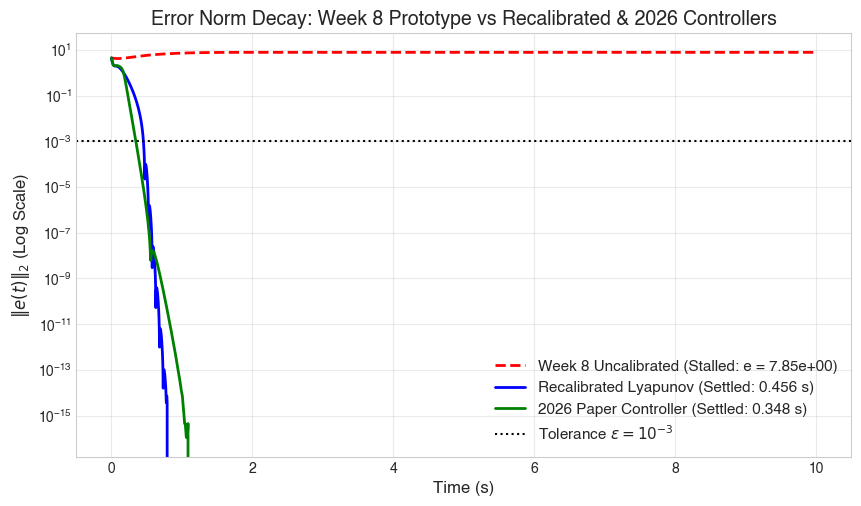

In [5]:
res_w8 = simulate("week8_uncalibrated")
res_rec = simulate("recalibrated_lyapunov", alpha=5.0, beta=5.0, p=1.2, q=0.7)
res_2026 = simulate("2026_paper", alpha=6.0, beta=6.0, p=1.3, gamma=5.0)

plt.figure(figsize=(10, 5.5))
plt.semilogy(res_w8['t'], res_w8['err_norm'], 'r--', label=f'Week 8 Uncalibrated (Stalled: e = {res_w8["final_err"]:.2e})', linewidth=2.0)
plt.semilogy(res_rec['t'], res_rec['err_norm'], 'b-', label=f'Recalibrated Lyapunov (Settled: {res_rec["ts"]:.3f} s)', linewidth=2.0)
plt.semilogy(res_2026['t'], res_2026['err_norm'], 'g-', label=f'2026 Paper Controller (Settled: {res_2026["ts"]:.3f} s)', linewidth=2.0)
plt.axhline(1e-3, color='k', linestyle=':', label='Tolerance $\epsilon = 10^{-3}$')
plt.xlabel('Time (s)', fontsize=12)
plt.ylabel(r'$\|e(t)\|_2$ (Log Scale)', fontsize=12)
plt.title('Error Norm Decay: Week 8 Prototype vs Recalibrated & 2026 Controllers', fontsize=14, fontweight='bold')
plt.legend(fontsize=11)
plt.grid(True, which='both', alpha=0.4)
plt.show()

## 4. Week 10 Task: Robustness Across Initial Conditions, Disturbances & Parameters

In [6]:
# Multi-initial condition evaluation (Fixed-Time Property)
ic_sets = [
    ("IC 1 (Small, ||e0||=0.32)", np.array([1.1, 1.8, 3.2, 3.9])),
    ("IC 2 (Moderate, ||e0||=4.47)", np.array([2.0, -1.0, 4.0, 1.0])),
    ("IC 3 (Large, ||e0||=10.54)", np.array([6.0, -3.0, 8.0, -2.0])),
    ("IC 4 (Extreme, ||e0||=22.27)", np.array([11.0, -8.0, 13.0, -10.0]))
]
plt.figure(figsize=(10, 5.5))
for label, x0_s_val in ic_sets:
    res = simulate("2026_paper", x0_s=x0_s_val, alpha=6.0, beta=6.0, p=1.3, gamma=5.0)
    plt.semilogy(res['t'], res['err_norm'], label=f'{label} -> $t_s = {res["ts"]:.3f}$ s', linewidth=2.0)
plt.axhline(1e-3, color='k', linestyle=':', label='Tol $10^{-3}$')
plt.axvline(2.5, color='m', linestyle='--', label='Theoretical Bound $T_{max} \approx 2.5$ s')
plt.xlabel('Time (s)', fontsize=12)
plt.ylabel(r'$\|e(t)\|_2$ (Log Scale)', fontsize=12)
plt.title('Fixed-Time Invariance Across Initial Conditions (2026 Controller)', fontsize=14, fontweight='bold')
plt.legend(fontsize=11)
plt.grid(True, which='both', alpha=0.4)
plt.show()

/var/folders/k0/g7h2q2sx6bl_c5wh7vk5pjnc0000gn/T/ipykernel_10203/3093057918.py:131: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  ctrl_effort = np.trapz(np.sum(U**2, axis=1), t_eval)
/var/folders/k0/g7h2q2sx6bl_c5wh7vk5pjnc0000gn/T/ipykernel_10203/3093057918.py:134: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  ise = np.trapz(err_norm**2, t_eval)
/var/folders/k0/g7h2q2sx6bl_c5wh7vk5pjnc0000gn/T/ipykernel_10203/3093057918.py:135: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  iae = np.trapz(err_norm, t_eval)
/var/folders/k0/g7h2q2sx6bl_c5wh7vk5pjnc0000gn/T/ipykernel_10203/3093057918.py:136: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.inte

ValueError: 
Theoretical Bound $T_{max} pprox 2.5$ s
                  ^
ParseException: Expected end of text, found '$'  (at char 18), (line:1, col:19)

<Figure size 1000x550 with 1 Axes>

## 5. Week 11 Task: Controller Benchmark Comparison (2026 Paper vs. 2022 Paper)

/var/folders/k0/g7h2q2sx6bl_c5wh7vk5pjnc0000gn/T/ipykernel_10203/3093057918.py:131: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  ctrl_effort = np.trapz(np.sum(U**2, axis=1), t_eval)
/var/folders/k0/g7h2q2sx6bl_c5wh7vk5pjnc0000gn/T/ipykernel_10203/3093057918.py:134: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  ise = np.trapz(err_norm**2, t_eval)
/var/folders/k0/g7h2q2sx6bl_c5wh7vk5pjnc0000gn/T/ipykernel_10203/3093057918.py:135: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  iae = np.trapz(err_norm, t_eval)
/var/folders/k0/g7h2q2sx6bl_c5wh7vk5pjnc0000gn/T/ipykernel_10203/3093057918.py:136: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.inte

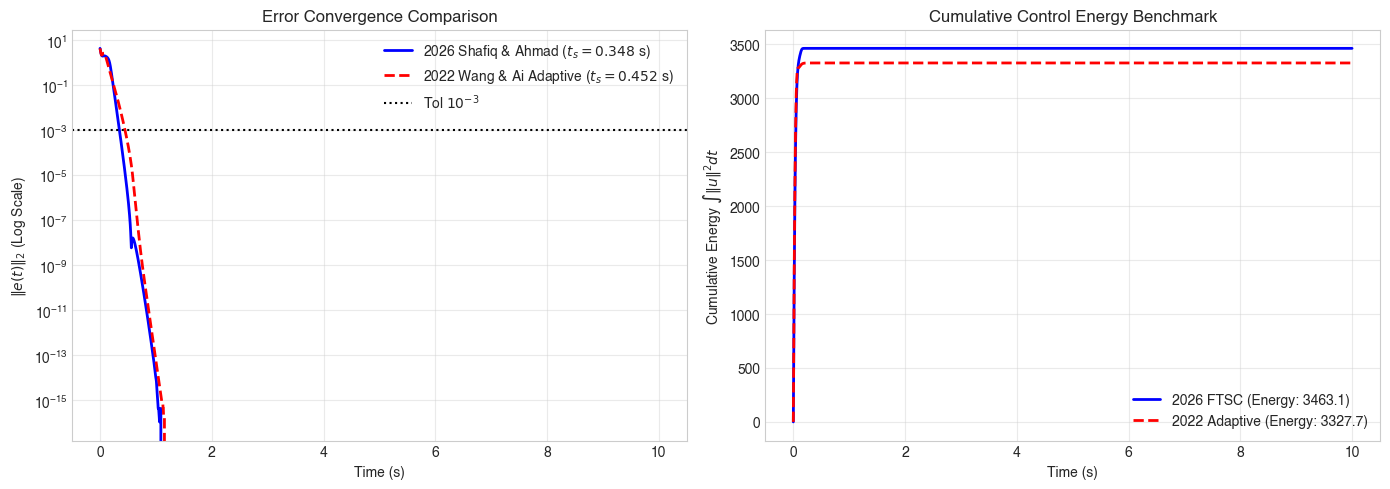

In [7]:
res_2026 = simulate("2026_paper", alpha=6.0, beta=6.0, p=1.3, gamma=5.0)
res_2022 = simulate("2022_adaptive_backstepping", alpha=5.0, beta=5.0, p=1.2, q=0.8)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.semilogy(res_2026['t'], res_2026['err_norm'], 'b-', label=f'2026 Shafiq & Ahmad ($t_s={res_2026["ts"]:.3f}$ s)', linewidth=2.0)
ax1.semilogy(res_2022['t'], res_2022['err_norm'], 'r--', label=f'2022 Wang & Ai Adaptive ($t_s={res_2022["ts"]:.3f}$ s)', linewidth=2.0)
ax1.axhline(1e-3, color='k', linestyle=':', label='Tol $10^{-3}$')
ax1.set_xlabel('Time (s)')
ax1.set_ylabel(r'$\|e(t)\|_2$ (Log Scale)')
ax1.set_title('Error Convergence Comparison', fontweight='bold')
ax1.legend()
ax1.grid(True, which='both', alpha=0.4)

cum_energy_2026 = spi.cumulative_trapezoid(np.sum(res_2026['U']**2, axis=1), res_2026['t'], initial=0)
cum_energy_2022 = spi.cumulative_trapezoid(np.sum(res_2022['U']**2, axis=1), res_2022['t'], initial=0)

ax2.plot(res_2026['t'], cum_energy_2026, 'b-', label=f'2026 FTSC (Energy: {res_2026["ctrl_effort"]:.1f})', linewidth=2.0)
ax2.plot(res_2022['t'], cum_energy_2022, 'r--', label=f'2022 Adaptive (Energy: {res_2022["ctrl_effort"]:.1f})', linewidth=2.0)
ax2.set_xlabel('Time (s)')
ax2.set_ylabel('Cumulative Energy $\int \|u\|^2 dt$')
ax2.set_title('Cumulative Control Energy Benchmark', fontweight='bold')
ax2.legend()
ax2.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()